# Batch Curation Poisoning — FVI with Per-Point Decomposition

Runs *Implementation Brief II* end-to-end on the reconstructed minimal Brief I
environment (linear-regression victim, online mini-batch GD):

1. Train the value function `V_hat(theta, t)` by fitted value iteration (FVI).
2. Compare the learned policy against the null / random / greedy baselines.
3. Produce the three diagnostic figures — the scientific payload:
   spectrum of `B`, relative interaction vs `eta`/`k`, and the three-tier gap.

The notebook must be run from the project directory (next to `env.py`, etc.).

## Setup

In [1]:
import os
import torch
import matplotlib.pyplot as plt
from IPython.display import Image, display

from config import EnvConfig, MethodConfig, tier_name
from env import Environment
from fvi import train_fvi, evaluate
from agents import NullAgent, RandomAgent, GreedyAgent, MethodAgent
from diagnostics import run_all_diagnostics

%matplotlib inline
torch.manual_seed(0)

## Configuration

`select_mode` controls how the *method* picks actions during training/eval
(`sort` | `lowrank` | `exact`). The diagnostics always compare all three tiers
regardless. With `d < m`, `B` is rank-deficient (rank <= min(m, d)).

In [10]:
env_cfg = EnvConfig(d=5, m=10, T=10, eta=0.2, noise=2)

cfg = MethodConfig(
    select_mode='sort',      # 'sort' | 'lowrank' | 'exact'
    rank_r=2,                # rank kept by lowrank
    use_hessian_in_B=True,   # False => Gram-only ablation
    K_iters=40,              # FVI outer iterations
    lam=1.0,
    weight_decay=1e-3,       # regularise V̂ curvature (see weight-decay sweep)
    c_edit=0.1,              # per-edit cost (raise to penalise editing)
    solver='gurobi',         # exact tier; falls back to brute force if unavailable
)

env = Environment(env_cfg, cfg)
print(env_cfg)
print(cfg)

EnvConfig(d=5, m=10, T=10, eta=0.2, noise=2, seed=0)
MethodConfig(hidden=(128, 128), K_iters=40, N_episodes=50, n_grad_steps=500, batch_size=256, buffer_capacity=20000, ema_decay=None, lr=0.001, weight_decay=0.001, eps_start=0.5, eps_end=0.05, use_hessian_in_B=True, select_mode='sort', rank_r=2, dual_iters=20, solver='gurobi', balance=True, k_max=None, c_edit=0.1, lam=1.0)


## Train the value function (FVI)

Each iteration collects rollouts under the current greedy policy (+ epsilon
exploration), then fits `V_hat` on Bellman targets against a frozen label network.

In [11]:
# return_history=True also records the method's held-out cost each iteration
V_psi, history = train_fvi(env, cfg, seed=0, return_history=True, best_checkpoint =True)

[FVI] iter  0  eps=0.500  loss=0.2884  mean_cost=9.5035
[FVI] iter  1  eps=0.488  loss=0.6074  mean_cost=7.6125
[FVI] iter  2  eps=0.477  loss=1.1421  mean_cost=7.6762
[FVI] iter  3  eps=0.465  loss=0.9361  mean_cost=7.6786
[FVI] iter  4  eps=0.454  loss=1.2904  mean_cost=7.6579
[FVI] iter  5  eps=0.442  loss=1.4869  mean_cost=7.6007
[FVI] iter  6  eps=0.431  loss=1.3760  mean_cost=7.7370
[FVI] iter  7  eps=0.419  loss=1.5845  mean_cost=7.8702
[FVI] iter  8  eps=0.408  loss=1.9441  mean_cost=7.8428
[FVI] iter  9  eps=0.396  loss=1.4624  mean_cost=7.7153
[FVI] iter 10  eps=0.385  loss=1.7955  mean_cost=7.4935
[FVI] iter 11  eps=0.373  loss=1.7746  mean_cost=7.3883
[FVI] iter 12  eps=0.362  loss=1.5715  mean_cost=7.3362
[FVI] iter 13  eps=0.350  loss=2.0380  mean_cost=7.3803
[FVI] iter 14  eps=0.338  loss=1.3334  mean_cost=7.4690
[FVI] iter 15  eps=0.327  loss=1.5425  mean_cost=7.5270
[FVI] iter 16  eps=0.315  loss=1.4874  mean_cost=7.5064
[FVI] iter 17  eps=0.304  loss=1.7176  mean_cost

## Method vs baselines

Mean episode cost (lower is better). The FVI policy should beat the myopic greedy
baseline because it accounts for the learned cost-to-go.

In [12]:
rng = torch.Generator().manual_seed(100)
agents = {
    'null':   NullAgent(),
    'random': RandomAgent(rng, cfg.balance, cfg.k_max),
    'greedy': GreedyAgent(env.victim, env.theta_target, cfg),
    tier_name(cfg.select_mode):
              MethodAgent(V_psi, env.victim, env.theta_target, cfg, rng),
}
costs = {name: evaluate(env, ag, rng, n_episodes=200) for name, ag in agents.items()}
for name, c in costs.items():
    print(f'{name:12s}: {c:.4f}')

plt.figure(figsize=(5, 3))
plt.bar(costs.keys(), costs.values(), color=['C3', 'C3', 'C1', 'C0'])
plt.ylabel('mean episode cost')
plt.title(f'{tier_name(cfg.select_mode)} vs baselines (lower is better)')
plt.tight_layout(); plt.show()

null    : 16.7915
random  : 23.7352
greedy  : 13.1571
method  : 7.4032


/tmp/ipykernel_307148/2485877827.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


## Cost across FVI iterations

The method's held-out cost at each FVI iteration, against the (constant) baselines.
Thanks to the **replay buffer** (`ReplayBuffer` in `fvi.py`), the value fit samples
data pooled across *all* iterations, so the TD bootstrap stays stable: the curve
drops below greedy within one iteration and **holds there** for the whole run.

Without replay (rebuilding the dataset from scratch each round) this same run
diverged — it climbed back above `null` as exploration decayed, because the data
collapsed onto the current policy's narrow trajectory. Accumulating transitions
across iterations is what fixes it.

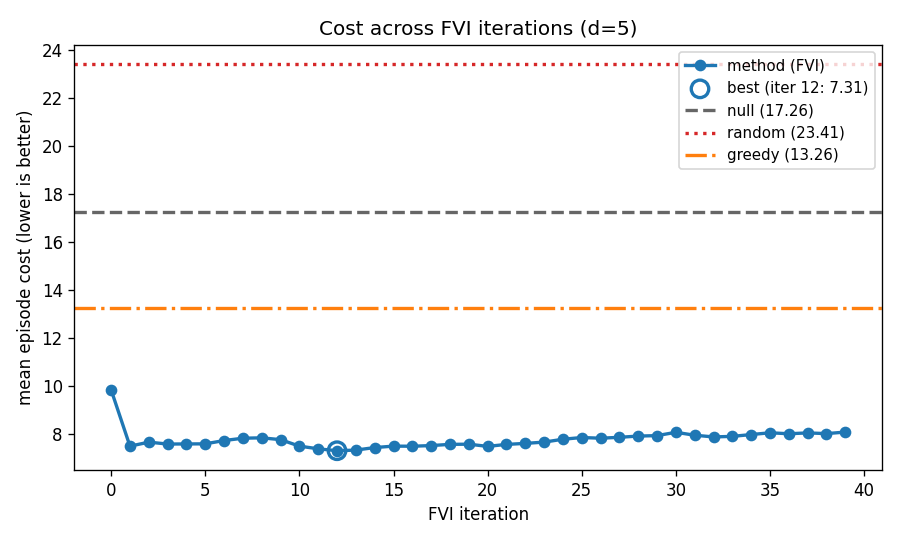

best method iter: 12 = 7.31


In [5]:
from viz import plot_training_curves

EVAL_SEED, EVAL_EP = 999, 100   # same held-out set train_fvi used for `history`
base_costs = {name: evaluate(env, agents[name],
                             torch.Generator().manual_seed(EVAL_SEED), n_episodes=EVAL_EP)
              for name in ['null', 'random', 'greedy']}

os.makedirs('figures', exist_ok=True)
plot_training_curves(history, base_costs, 'figures/fig0_training_curve.png',
                     title=f'Cost across FVI iterations (d={env.d})',
                     name=tier_name(cfg.select_mode))
display(Image(filename='figures/fig0_training_curve.png'))
print('best iter:', min(range(len(history)), key=lambda i: history[i]),
      '=', round(min(history), 2))

## Attack cost vs edit budget

How effective the attack is as a function of the curator's power — the delete
budget `k_max` (with balance, also the number of duplicates). For each budget the
method is **retrained** under that constraint (the value function depends on it),
then scored on the held-out set.

- **Budget 0** forbids edits, so method = greedy = null (no attack).
- Cost falls as the budget grows — more edits let the attacker push θ toward θ̃.
- The **method stays below greedy at every budget**: planning spends the edit
  allowance more efficiently. (The true frontier is monotone in budget; small
  wiggles are per-budget training variance.)

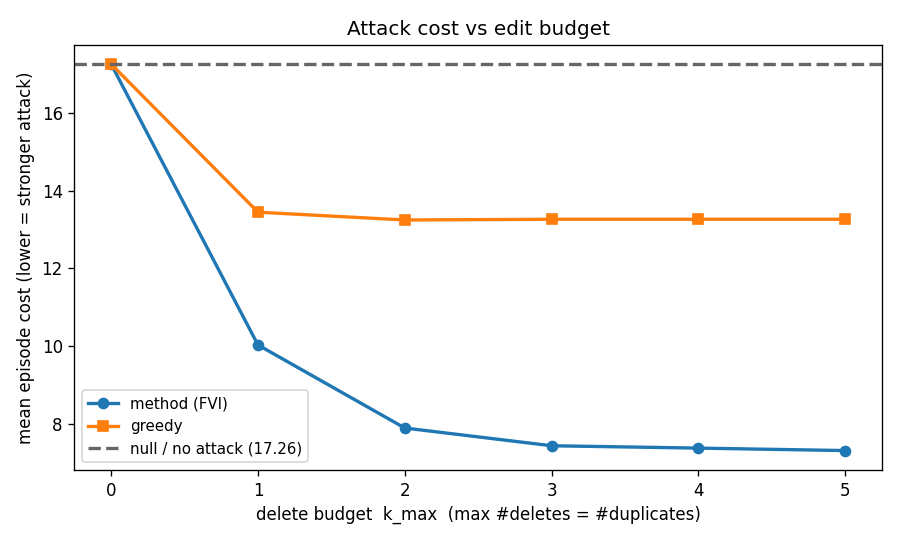

method cost by budget: [17.26, 10.03, 7.89, 7.43, 7.37, 7.31]
greedy cost by budget: [17.26, 13.44, 13.24, 13.26, 13.26, 13.26]


In [6]:
from viz import cost_vs_budget

os.makedirs('figures', exist_ok=True)
# Retrains the method once per budget, so this is the slowest cell.
budget_res = cost_vs_budget(env_cfg, cfg, budgets=range(0, env_cfg.m // 2 + 1),
                            path='figures/fig5_cost_vs_budget.png', eval_episodes=100)
display(Image(filename='figures/fig5_cost_vs_budget.png'))
_nm = tier_name(cfg.select_mode)
print(f'{_nm} cost by budget:', [round(x, 2) for x in budget_res[_nm]])
print('greedy cost by budget:', [round(x, 2) for x in budget_res['greedy']])

## Method advantage vs model dimension d

Does the method's edge over greedy grow with the model dimension `d`? Everything is
held fixed except `d`; method and greedy use the same selector, so the only
difference is the learned cost-to-go. Raw cost grows with `d` (left, log scale), so
the test is the scale-free **advantage** `(greedy − method)/greedy` (right).

Finding: the advantage is an **inverted-U** — it rises steeply from d=1, peaks around
d≈3, then declines. Greedy's myopia hurts more as the model grows complex, but with
fixed attacker resources (m, T) the attack weakens for *everyone* at high d, and the
value function is harder to learn — so the gap narrows again. The method still beats
greedy at every d tested.

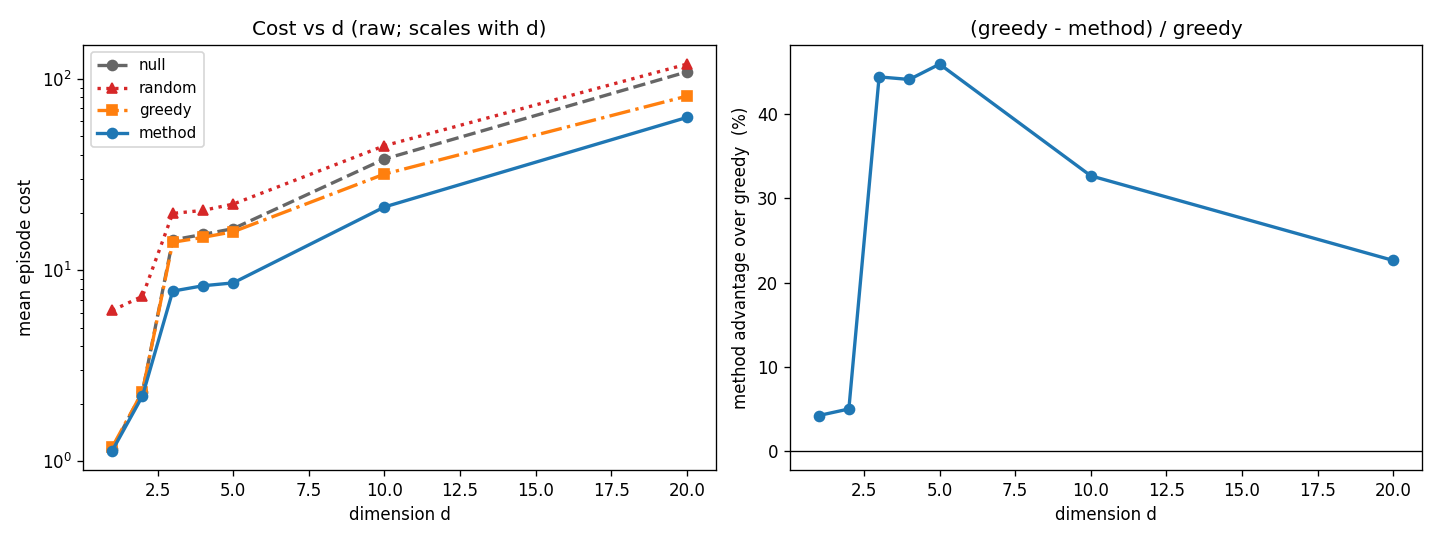

advantage % by d: [4.2, 5.0, 44.5, 44.2, 46.0, 32.7, 22.6]


In [7]:
from viz import cost_vs_dimension

os.makedirs('figures', exist_ok=True)
# Slow cell: retrains once per dimension. Add seeds=(0, 1, 2) to smooth the curve.
dim_res = cost_vs_dimension(EnvConfig(m=10, T=10, eta=0.2, noise=0.1),
                            MethodConfig(select_mode='sort', K_iters=40, c_edit=0.1),
                            ds=[1, 2, 3, 4, 5, 10, 20],
                            path='figures/fig7_cost_vs_dim.png', seeds=(0,1,2))
display(Image(filename='figures/fig7_cost_vs_dim.png'))
print('advantage % by d:', [round(x, 1) for x in dim_res['advantage_pct']])

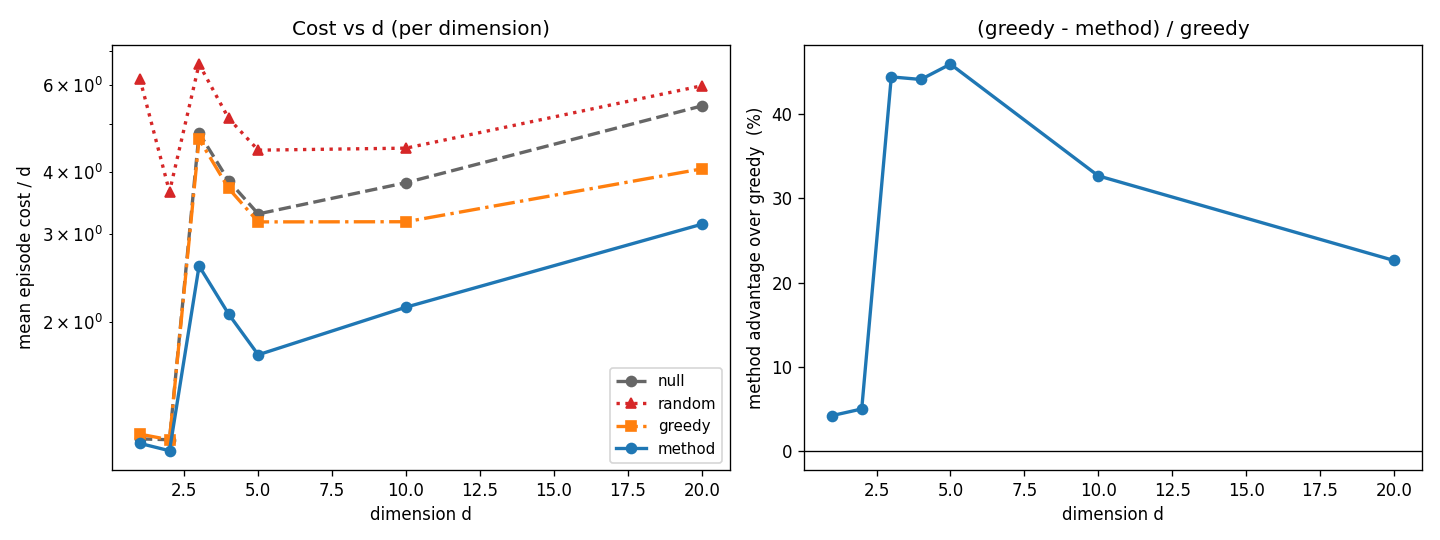

advantage % by d: [4.2, 5.0, 44.5, 44.2, 46.0, 32.7, 22.6]


In [8]:
from viz import cost_vs_dimension

os.makedirs('figures', exist_ok=True)
# Slow cell: retrains once per dimension. Add seeds=(0, 1, 2) to smooth the curve.
dim_res = cost_vs_dimension(EnvConfig(m=10, T=10, eta=0.2, noise=0.1),
                            MethodConfig(select_mode='sort', K_iters=40, c_edit=0.1),
                            ds=[1, 2, 3, 4, 5, 10, 20],
                            path='figures/fig7_cost_vs_dim_norm.png', seeds=(0,1,2), normalize="d")
display(Image(filename='figures/fig7_cost_vs_dim_norm.png'))
print('advantage % by d:', [round(x, 1) for x in dim_res['advantage_pct']])

## Selection tiers vs dimension d

Does using the interaction term `B` (via `lowrank` / `exact`) buy more than
first-order `sort` as `d` grows? For each `d` we train **one** value function and
evaluate that same `V̂` with each selector, so only the selection tier varies (the
fig-3 comparison, swept over d).

Finding: `exact ≤ lowrank ≤ sort` holds end-to-end, but the benefit of `B` over
`sort` is **modest (~5–10%) and does not grow with d** — noisy, with occasional
spikes. Over a full rollout a decent `V̂` dominates the trajectory, so the selector's
large *per-step* edge (fig 3) mostly washes out. `lowrank` keeps rank 2, so it
captures less of `B` as `rank(B)` grows with `d`, tracking closer to `sort`.

Restricted license - for non-production use only - expires 2027-11-29


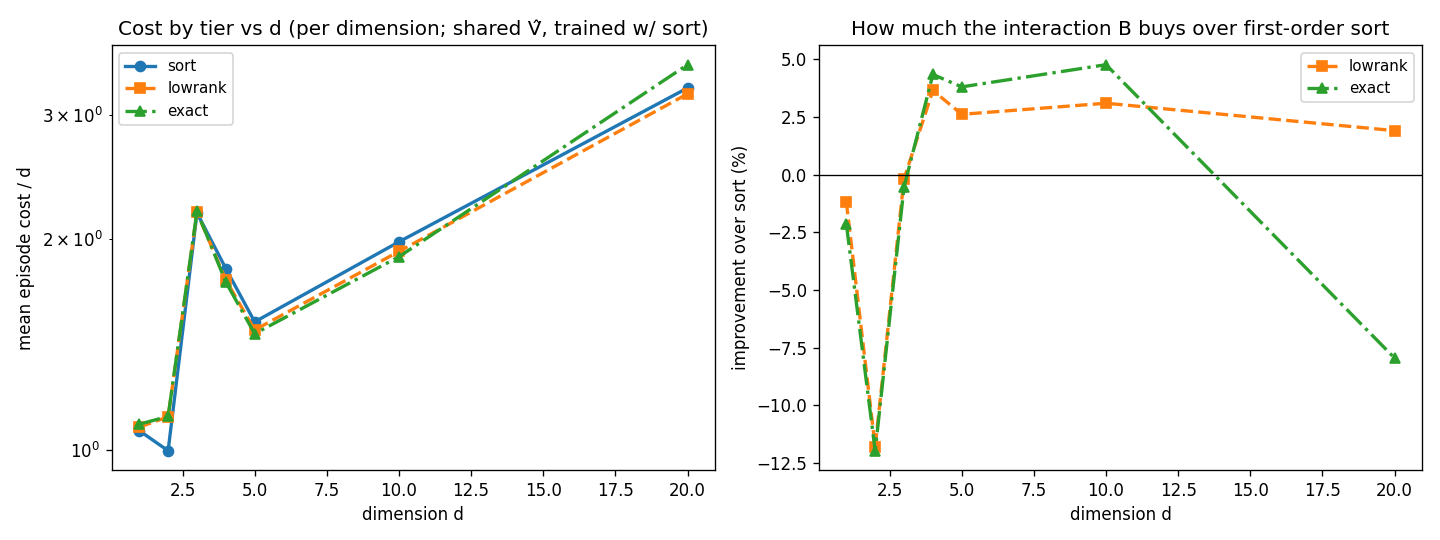

exact improvement over sort %: [-2.1, -12.0, -0.5, 4.3, 3.8, 4.8, -8.0]


In [9]:
from viz import cost_vs_dimension_tiers
import numpy as np

os.makedirs('figures', exist_ok=True)
# Slow cell: trains once per d and evaluates all three tiers (exact uses the solver).
tier_res = cost_vs_dimension_tiers(EnvConfig(m=10, T=10, eta=0.2, noise=2),
                                   MethodConfig(K_iters=40, rank_r=2, c_edit=0.1),
                                   ds=[1, 2, 3, 4, 5, 10, 20],
                                   path='figures/fig8_tiers_vs_dim.png', seeds=(0, 1, 2), normalize="d")
display(Image(filename='figures/fig8_tiers_vs_dim.png'))
s = np.array(tier_res['sort'])
print('exact improvement over sort %:',
      [round(x, 1) for x in (s - np.array(tier_res['exact'])) / s * 100])

## Distance to target ‖θ_t − θ̃‖ vs dimension d

Same dimension sweeps as above, but the y-axis is the **distance to the attacker's
target**, `mean ‖θ_t − θ̃‖` over the trajectory (the quantity the nefarious cost is
built from), instead of episode cost. Two separate comparisons:

1. **Method vs baselines** — the method here uses **`sort`** selection.
2. **Selection tiers** — `sort` / `lowrank` / `exact` sharing one `V̂` per d.

The inverted-U over d and the `exact ≤ lowrank ≤ sort` sandwich both reappear in
distance terms — the same story as the cost plots, in parameter-distance units.

In [ ]:
from viz import cost_vs_dimension, cost_vs_dimension_tiers
os.makedirs('figures', exist_ok=True)

# Plot 1: first-order selection vs null / random / greedy, y = distance to target
gap1 = cost_vs_dimension(EnvConfig(m=8, T=6, eta=0.2, noise=0.1),
                         MethodConfig(select_mode='sort', K_iters=15, c_edit=0.0),
                         ds=[1, 2, 3, 4, 6, 8, 12],
                         path='figures/fig9_gap_vs_dim.png', seeds=(0, 1), metric='gap')
display(Image(filename='figures/fig9_gap_vs_dim.png'))

In [ ]:
# Plot 2: selection tiers (sort / lowrank / exact), y = distance to target
gap2 = cost_vs_dimension_tiers(EnvConfig(m=8, T=6, eta=0.2, noise=0.1),
                               MethodConfig(K_iters=15, rank_r=2, c_edit=0.0),
                               ds=[1, 2, 3, 4, 6, 8],
                               path='figures/fig10_gap_vs_dim_tiers.png',
                               seeds=(0, 1), eval_episodes=60, metric='gap')
display(Image(filename='figures/fig10_gap_vs_dim_tiers.png'))

## Diagnostics — the scientific payload

- **fig 1 (spectrum of B):** with `d < m`, exactly `m - d` eigenvalues are ~0;
  the cumulative trace fraction shows how few directions carry the interaction.
- **fig 2 (relative interaction):** `|1/2 aᵀBa| / |aᵀα|` scales ~linearly in `eta`.
- **fig 3 (tier gap):** `cost(exact) <= cost(lowrank) <= cost(sort)` — the price of
  ignoring the interaction is the headline result.

In [ ]:
outdir = 'figures'
os.makedirs(outdir, exist_ok=True)
summary = run_all_diagnostics(env, cfg, V_psi, outdir=outdir, n_episodes=30)
print('tier costs:', {k: round(v, 4) for k, v in summary['cost'].items()})
print('tier times:', {k: round(v, 5) for k, v in summary['time'].items()})

for fname in ['fig1_spectrum.png', 'fig2_rel_interaction.png', 'fig3_tiers.png']:
    display(Image(filename=os.path.join(outdir, fname)))

## Low-rank duality gap over iterations

The `lowrank` tier solves its rank-r relaxation by dual ascent and reports a
**duality gap** as a certificate (`lowrank_gap_trace` / `_select_lowrank`). Here we
trace that gap across the dual-ascent iterations, over states the policy visits.

The gap **collapses in ~2 iterations**, then plateaus at a positive residual — the
genuine integrality gap of the (nonconvex, binary) problem, which dual ascent cannot
close. Some states start at gap 0 (sort is already optimal for the rank-r objective);
a few dip slightly negative when a negative eigenvalue is kept, where the bound is
only heuristic (B need not be PSD).

In [ ]:
from viz import plot_duality_gap

os.makedirs('figures', exist_ok=True)
dg = plot_duality_gap(env, V_psi, cfg, 'figures/fig11_duality_gap.png',
                      rng=torch.Generator().manual_seed(7), n_states=24, dual_iters=25)
display(Image(filename='figures/fig11_duality_gap.png'))
print('mean gap per iter:', [round(x, 4) for x in dg['mean_gap'][:6]], '...')

## Weight decay: curvature vs performance

Sweeping the value-net's weight decay while monitoring both the **curvature** of `V̂`
(||Hessian part of B|| / ||Gram part||, red, log axis) and **attack performance**
(mean episode cost, blue). Weight decay caps how wiggly `V̂` can be — a network's
curvature is bounded by products of its weight norms — so it attacks the overfitting
at its source, unlike Polyak averaging (which averages an already-overfit net) or
early stopping (which discards later training).

Both improve together: curvature falls monotonically and cost *drops* up to
`wd≈1e-2`, then over-regularization nudges cost back up at `1e-1`. So `wd≈1e-3–1e-2`
is the sweet spot — a smooth `V̂` (valid `B` and duality gaps) **and** a stronger
attack, with the final checkpoint already well-conditioned.

In [ ]:
from viz import plot_weight_decay_sweep

os.makedirs('figures', exist_ok=True)
# Slow cell: trains once per weight-decay value (x seeds).
wd_res = plot_weight_decay_sweep(EnvConfig(d=5, m=8, T=6, eta=0.2),
                                 MethodConfig(select_mode='sort', K_iters=20, c_edit=0.0),
                                 wds=[0, 1e-4, 1e-3, 1e-2, 1e-1],
                                 path='figures/fig12_weight_decay.png', seeds=(0, 1))
display(Image(filename='figures/fig12_weight_decay.png'))
print('hess_ratio:', [round(x, 2) for x in wd_res['hess_ratio']])
print('cost      :', [round(x, 2) for x in wd_res['cost']])

## Inspect the decomposition at a single state

Per-step diagnostics from `interaction_diagnostics`: the neglected interaction
magnitude, the spectrum, how far first-order `sort` sits from `exact`, and the
fraction of points on which the two agree.

In [ ]:
from decomposition import scores_and_interaction
from selection import select_action
from diagnostics import interaction_diagnostics

rng2 = torch.Generator().manual_seed(7)
theta = env.theta_0.clone()
z = env.stream.sample_batch(env.m, rng2)
t = 0

Phi = env.victim.phi_batch(theta, z)
alpha, B = scores_and_interaction(V_psi, theta, z, t, env.victim, env.theta_target,
                                  cfg.lam, need_B=True, use_hessian=cfg.use_hessian_in_B)
a_sort = select_action(alpha, B, 'sort', c_edit=cfg.c_edit, balance=cfg.balance)
a_exact = select_action(alpha, B, 'exact', c_edit=cfg.c_edit, balance=cfg.balance,
                        solver=cfg.solver)

diag = interaction_diagnostics(alpha, B, a_sort, a_exact, Phi, cfg.lam, cfg.c_edit)
for k, v in diag.items():
    print(f'{k:18s}: {v.round(4) if k == "spectrum" else v}')
print('a_sort :', a_sort.tolist())
print('a_exact:', a_exact.tolist())

## d = 1: visualizing the attack on the regression line

With a single feature the victim's model is a line `y = θ·x`, so we can literally
watch the attacker steer it. A few setup notes:

- **Higher label noise** (`noise=2.0`) keeps per-point gradients large and varied
  near convergence — that is what gives the curator leverage. With tiny noise the
  residuals vanish at θ* and the line can barely be moved.
- The attacker targets a **steeper** slope (`θ̃=3.0` vs true `θ*≈1.5`): it deletes
  points that pull the slope down and duplicates points that pull it up.
- `c_edit=0` here, so the problem is near-myopic (greedy is already strong). This
  section is about *seeing* the attack, not the planning gap (that is the d=5 part).

**Left:** clean SGD recovers the true slope; the attacked line is dragged to the
target. **Right:** the slope θ_t over the episode — attacked shoots to θ̃ and holds,
clean settles at θ*.

In [13]:
from viz import plot_regression_attack

env1_cfg = EnvConfig(d=1, m=10, T=10, eta=0.3, noise=2.0)  # noise => attacker leverage
cfg1 = MethodConfig(select_mode='exact', K_iters=15, N_episodes=40, lam=1.0, c_edit=0.0)

torch.manual_seed(0)
env1 = Environment(env1_cfg, cfg1)
env1.theta_target = torch.tensor([3.0])   # steeper-line target; set BEFORE training
print(f'true slope θ*={float(env1.stream.theta_star):.2f}  target θ̃={float(env1.theta_target):.2f}')

V1 = train_fvi(env1, cfg1, seed=0, verbose=False)

true slope θ*=1.54  target θ̃=3.00


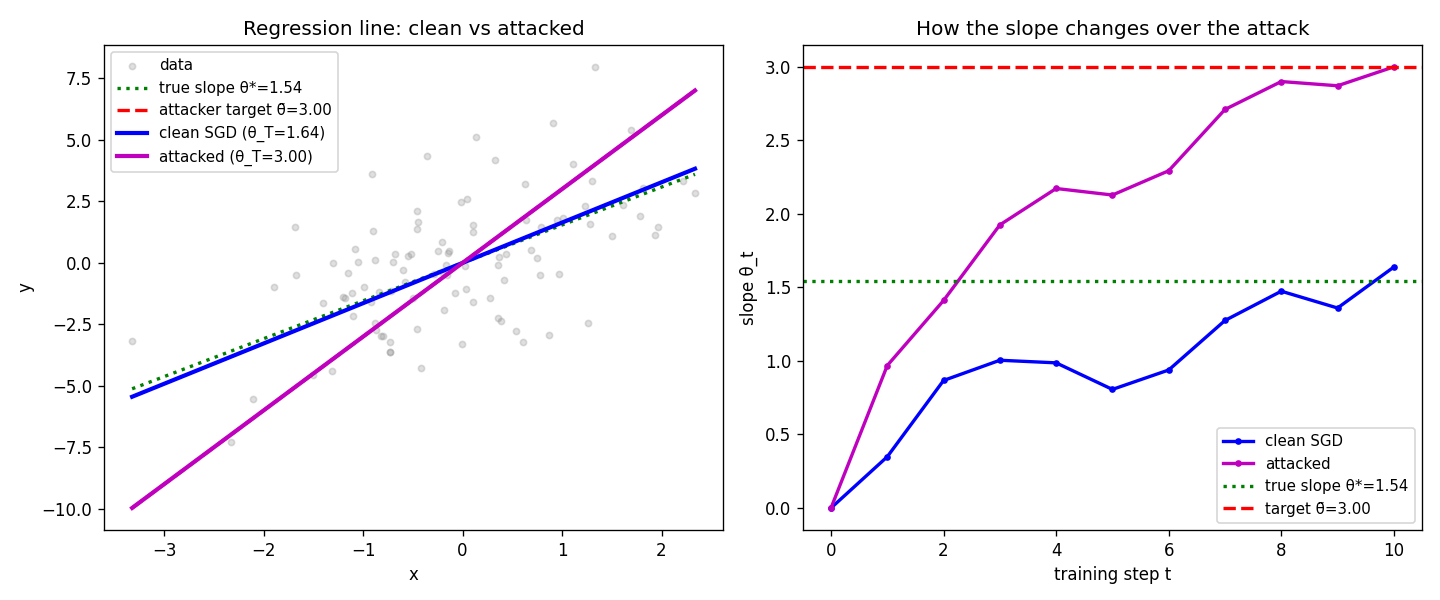

attacked slope θ_t: [0.0, 0.97, 1.41, 1.92, 2.17, 2.13, 2.29, 2.71, 2.9, 2.87, 3.0]
clean    slope θ_t: [0.0, 0.35, 0.87, 1.0, 0.99, 0.81, 0.94, 1.28, 1.47, 1.36, 1.64]


In [14]:
method1 = MethodAgent(V1, env1.victim, env1.theta_target, cfg1,
                      torch.Generator().manual_seed(1))

os.makedirs('figures', exist_ok=True)
info = plot_regression_attack(env1, method1, 'figures/fig4_regression_attack.png',
                              rng=torch.Generator().manual_seed(7))
display(Image(filename='figures/fig4_regression_attack.png'))
print('attacked slope θ_t:', [round(x, 2) for x in info['attacked_traj']])
print('clean    slope θ_t:', [round(x, 2) for x in info['clean_traj']])

### Per-policy action map

The same episode under each policy, with **every data point flagged by the action
taken on it** — delete (red ✕), duplicate (green ●), or keep (grey). This exposes
the attacker's *strategy*: to steepen the line toward θ̃ it **duplicates** points
that rotate the slope up and **deletes** points that pull it down. `null` edits
nothing, `random` edits without pattern, while `greedy` / `method` show a coherent
structure. (Once the attack succeeds the target line sits under the fitted line.)

In [ ]:
from viz import plot_regression_attack_grid

policies = {
    'null':         NullAgent(),
    'random':       RandomAgent(torch.Generator().manual_seed(2), cfg1.balance, cfg1.k_max),
    'greedy':       GreedyAgent(env1.victim, env1.theta_target, cfg1, mode=cfg1.select_mode),
    tier_name(cfg1.select_mode):
                    MethodAgent(V1, env1.victim, env1.theta_target, cfg1,
                                torch.Generator().manual_seed(1)),
}
os.makedirs('figures', exist_ok=True)
res = plot_regression_attack_grid(env1, policies, 'figures/fig6_action_map.png',
                                  rng=torch.Generator().manual_seed(7))
display(Image(filename='figures/fig6_action_map.png'))
for name, r in res.items():
    print(f"{name:14s}: theta_T={r['theta_T']:.2f}  "
          f"deletes={r['n_delete']}  dups={r['n_dup']}")

## Visualizing the attack for d > 1 (parameter space)

With `d=5` there's no single regression line (the model is a hyperplane), so we
visualize the attack in **parameter space** instead:

- **Left:** the θ trajectory projected onto the plane spanned by θ* and θ̃. Clean SGD
  heads to θ* (true); the attacked run is **bent toward the target θ̃**.
- **Right:** the final regression coefficients — each attacked coefficient is pulled
  from θ* toward θ̃.

(Self-contained cell with `c_edit=0` for a clear, strong attack; raising `c_edit`
shrinks the bend, as the edit-cost sweep showed.)

In [ ]:
from viz import plot_attack_paramspace

torch.manual_seed(0)
env5_cfg = EnvConfig(d=5, m=10, T=10, eta=0.2)
cfg5 = MethodConfig(select_mode='sort', K_iters=20, lam=1.0, c_edit=0.0, weight_decay=1e-3)
env5 = Environment(env5_cfg, cfg5)
V5 = train_fvi(env5, cfg5, seed=0, verbose=False, best_checkpoint=True)
method5 = MethodAgent(V5, env5.victim, env5.theta_target, cfg5,
                      torch.Generator().manual_seed(1))

os.makedirs('figures', exist_ok=True)
plot_attack_paramspace(env5, method5, 'figures/fig13_attack_d5.png',
                       rng=torch.Generator().manual_seed(7))
display(Image(filename='figures/fig13_attack_d5.png'))